# 02 – Training a U-Net on Sentinel-1 patches

Input: VV, VH and VV − VH (all in dB), 256 × 256 pixels.
Output: one of 7 land cover classes per pixel.

Two model variants are trained on exactly the same data:

1. **U-Net from scratch** – encoder and decoder learned from our data only
2. **U-Net with a ResNet50 encoder pretrained on ImageNet** – transfer learning (lecture 08)

Rules used everywhere in this notebook:
- Pixels with label 255 (no data, snow) are left out of the loss **and** of every metric.
- Clipping limits, mean and standard deviation are computed on the **training set only** and saved,
  so validation, test and the prototype use the same numbers.
- The test set is used only once, at the end, for the selected model.

# Preliminaries

In [1]:
from pathlib import Path
import shutil

# Search for the patches folder in Kaggle input directories
input_dir = Path("/kaggle/input")
found_patches = None

for path in input_dir.rglob("patches"):
    if path.is_dir():
        found_patches = path
        break

if found_patches:
    dest = Path("data/patches")
    if dest.exists():
        shutil.rmtree(dest)
    shutil.copytree(found_patches, dest)
    print("Successfully copied patches to data/patches!")
    print("Files found:", [f.name for f in dest.iterdir()])
else:
    print("Patches folder not found in /kaggle/input. Make sure you attached the output dataset from Notebook 1 via '+ Add Input' on the right panel.")

Successfully copied patches to data/patches!
Files found: ['train_y.npy', 'test_x.npy', 'test_y.npy', 'test_meta.csv', 'train_meta.csv', 'classes.json', 'validation_x.npy', 'validation_meta.csv', 'train_x.npy', 'validation_y.npy']


In [2]:
%%writefile requirements.txt
earthengine-api==1.7.49
rasterio==1.4.4
numpy==2.3.2
tensorflow==2.20.0
requests
matplotlib

Overwriting requirements.txt


In [3]:
%pip install -q -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [4]:
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

import tensorflow as tf
import keras
from keras import layers

# Fix seeds for (hopefully) reproducible results
np.random.seed(14)
tf.random.set_seed(19)
keras.utils.set_random_seed(19)

print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.20.0 | Keras: 3.13.2
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


# Data

In [5]:
from pathlib import Path

required = ["classes.json"] + [
    f"{split}_{suffix}"
    for split in ("train", "validation", "test")
    for suffix in ("x.npy", "y.npy", "meta.csv")
]

patch_folders = []
for file in Path("/kaggle/input").rglob("classes.json"):
    folder = file.parent
    missing = [name for name in required if not (folder / name).is_file()]
    if missing:
        print("Incomplete folder:", folder)
        print("Missing files:", missing)
    else:
        patch_folders.append(folder)
        print("Complete patch folder:", folder)

print("Complete folders found:", len(patch_folders))

Complete patch folder: /kaggle/input/notebooks/ishwarithakur/01-prepare-dataset-ipynb/data/patches
Complete folders found: 1


In [6]:
patch_folder = Path("data/patches")
model_folder = Path("models")
model_folder.mkdir(exist_ok=True)

class_info = json.loads((patch_folder / "classes.json").read_text())
CLASSES = class_info["classes"]
IGNORE = class_info["ignore"]
N_CLASSES = len(CLASSES)
COLORS = ["#006400", "#ffff4c", "#f096ff", "#fa0000", "#b4b4b4", "#0064c8", "#0096a0"]

data = {}
for split in ["train", "validation", "test"]:
    x = np.load(patch_folder / f"{split}_x.npy")
    y = np.load(patch_folder / f"{split}_y.npy")
    meta = (patch_folder / f"{split}_meta.csv").read_text().strip().split("\n")[1:]
    data[split] = {"x": x, "y": y, "meta": [row.split(",") for row in meta]}
    print(f"{split:<11} x {x.shape} {x.dtype} | y {y.shape} {y.dtype}")

train       x (2920, 256, 256, 2) float16 | y (2920, 256, 256) uint8
validation  x (864, 256, 256, 2) float16 | y (864, 256, 256) uint8
test        x (864, 256, 256, 2) float16 | y (864, 256, 256) uint8


## Class distribution and class weights

Classes are unbalanced, so rare classes get a higher weight in the loss
(median frequency balancing, capped at 10).

In [7]:
counts = np.bincount(data["train"]["y"][data["train"]["y"] != IGNORE].ravel(), minlength=N_CLASSES)
frequency = counts / counts.sum()

present = frequency > 0
class_weights = np.zeros(N_CLASSES, dtype=np.float32)
class_weights[present] = np.median(frequency[present]) / frequency[present]
class_weights = np.clip(class_weights, 0, 10)

for name, f, w in zip(CLASSES, frequency, class_weights):
    print(f"{name:<26} {100 * f:6.2f}%   weight {w:5.2f}")

Trees (incl. mangroves)     24.40%   weight  0.62
Grassland / shrubland       15.24%   weight  1.00
Cropland                    15.91%   weight  0.96
Built-up                    36.08%   weight  0.42
Bare / sparse vegetation     2.45%   weight  6.23
Permanent water              5.42%   weight  2.81
Herbaceous wetland           0.49%   weight 10.00


## Normalisation (training data only)

1. Clip VV and VH to their 0.5% and 99.5% percentiles (very bright city pixels reach +28 dB)
2. Add VV − VH as a third channel (the ratio in dB, often used for SAR land cover)
3. Subtract the mean and divide by the standard deviation

The values are saved in `models/normalisation.json` for the prototype.

In [8]:
ADD_RATIO = True

# every 4th pixel is enough to estimate the statistics and saves memory
sample = data["train"]["x"][:, ::4, ::4, :].astype(np.float32).reshape(-1, 2)

clip_low = np.percentile(sample, 0.5, axis=0)
clip_high = np.percentile(sample, 99.5, axis=0)

sample = np.clip(sample, clip_low, clip_high)
if ADD_RATIO:
    sample = np.concatenate([sample, sample[:, :1] - sample[:, 1:2]], axis=1)

channel_mean = sample.mean(axis=0)
channel_std = sample.std(axis=0)
del sample

normalisation = {
    "channels": ["VV", "VH", "VV-VH"] if ADD_RATIO else ["VV", "VH"],
    "add_ratio": ADD_RATIO,
    "clip_low": clip_low.tolist(),
    "clip_high": clip_high.tolist(),
    "mean": channel_mean.tolist(),
    "std": channel_std.tolist(),
}
(model_folder / "normalisation.json").write_text(json.dumps(normalisation, indent=2))
print(json.dumps(normalisation, indent=2))

{
  "channels": [
    "VV",
    "VH",
    "VV-VH"
  ],
  "add_ratio": true,
  "clip_low": [
    -23.09375,
    -30.546875
  ],
  "clip_high": [
    6.453125,
    -2.4609375
  ],
  "mean": [
    -9.366817474365234,
    -16.796506881713867,
    7.3199687004089355
  ],
  "std": [
    4.857954025268555,
    5.062873363494873,
    2.994724988937378
  ]
}


In [9]:
N_CHANNELS = 3 if ADD_RATIO else 2


def normalise(x):
    x = tf.cast(x, tf.float32)
    x = tf.clip_by_value(x, clip_low, clip_high)
    if ADD_RATIO:
        x = tf.concat([x, x[..., :1] - x[..., 1:2]], axis=-1)
    return (x - channel_mean) / channel_std


def augment(x, y):
    # flip and rotate image and label together
    xy = tf.concat([x, tf.cast(y[..., tf.newaxis], tf.float32)], axis=-1)
    xy = tf.image.random_flip_left_right(xy)
    xy = tf.image.random_flip_up_down(xy)
    xy = tf.image.rot90(xy, k=tf.random.uniform([], 0, 4, dtype=tf.int32))
    return xy[..., :-1], tf.cast(xy[..., -1], tf.uint8)


BATCH_SIZE = 16


def make_dataset(split, training=False):
    ds = tf.data.Dataset.from_tensor_slices((data[split]["x"], data[split]["y"]))
    if training:
        ds = ds.shuffle(len(data[split]["x"]), seed=14)
    ds = ds.map(lambda x, y: (normalise(x), y), num_parallel_calls=tf.data.AUTOTUNE)
    if training:
        ds = ds.map(augment, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


train_ds = make_dataset("train", training=True)
valid_ds = make_dataset("validation")
test_ds = make_dataset("test")

# Loss and metrics that ignore label 255

Keras' cross-entropy would fail (or learn nonsense) on label 255, so we write the loss ourselves:
pixels with 255 get weight 0, all other pixels get their class weight.

In [10]:
weights_tensor = tf.constant(class_weights)


def masked_loss(y_true, y_pred):
    y_true = tf.cast(y_true, tf.int32)
    valid = tf.not_equal(y_true, IGNORE)
    y_safe = tf.where(valid, y_true, 0)                       # any real class, it gets weight 0 anyway

    pixel_loss = keras.losses.sparse_categorical_crossentropy(y_safe, y_pred)
    pixel_weight = tf.gather(weights_tensor, y_safe) * tf.cast(valid, tf.float32)

    return tf.reduce_sum(pixel_loss * pixel_weight) / tf.maximum(tf.reduce_sum(pixel_weight), 1.0)


def masked_accuracy(y_true, y_pred):
    y_true = tf.cast(y_true, tf.int32)
    valid = tf.not_equal(y_true, IGNORE)
    correct = tf.equal(tf.cast(tf.argmax(y_pred, axis=-1), tf.int32), y_true)
    return tf.reduce_sum(tf.cast(correct & valid, tf.float32)) / tf.maximum(
        tf.reduce_sum(tf.cast(valid, tf.float32)), 1.0)

For IoU we collect a confusion matrix over a whole split (again without 255 pixels).

- **IoU** of a class = correct pixels / (pixels that are this class + pixels predicted as this class − correct pixels)
- **mIoU** = mean IoU over the classes

In [11]:
def predict_split(model, dataset):
    return np.concatenate([np.argmax(model.predict_on_batch(xb), axis=-1) for xb, _ in dataset]).astype(np.uint8)


def confusion(y_true, y_pred):
    valid = y_true != IGNORE
    index = N_CLASSES * y_true[valid].astype(np.int64) + y_pred[valid]
    return np.bincount(index, minlength=N_CLASSES ** 2).reshape(N_CLASSES, N_CLASSES)


def scores(cm):
    tp = np.diag(cm).astype(float)
    with np.errstate(divide="ignore", invalid="ignore"):
        iou = tp / (cm.sum(0) + cm.sum(1) - tp)
        precision = tp / cm.sum(0)
        recall = tp / cm.sum(1)
        f1 = 2 * precision * recall / (precision + recall)
    return {"oa": tp.sum() / cm.sum(), "miou": np.nanmean(iou), "iou": iou, "f1": f1}


class ValidationIoU(keras.callbacks.Callback):
    # adds val_miou to the logs after every epoch
    def __init__(self, dataset, y_true):
        super().__init__()
        self.dataset = dataset
        self.y_true = y_true

    def on_epoch_end(self, epoch, logs=None):
        y_pred = predict_split(self.model, self.dataset)
        logs["val_miou"] = scores(confusion(self.y_true, y_pred))["miou"]
        print(f" - val_miou: {logs['val_miou']:.4f}")

# Models

### Variant 1: U-Net from scratch

Encoder: 4 times (two 3×3 convolutions + max pooling). Decoder: 4 times (upsampling + skip connection
from the encoder + two 3×3 convolutions). The skip connections bring back the fine detail that pooling removes.

In [12]:
def conv_block(x, filters):
    for _ in range(2):
        x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
    return x


def build_unet(base_filters=32, dropout=0.3):
    inputs = keras.Input(shape=(256, 256, N_CHANNELS))

    skips = []
    x = inputs
    for level in range(4):                                  # 256 -> 128 -> 64 -> 32 -> 16
        x = conv_block(x, base_filters * 2 ** level)
        skips.append(x)
        x = layers.MaxPooling2D()(x)

    x = conv_block(x, base_filters * 16)
    x = layers.Dropout(dropout)(x)

    for level in reversed(range(4)):                        # 16 -> 32 -> 64 -> 128 -> 256
        x = layers.Conv2DTranspose(base_filters * 2 ** level, 2, strides=2, padding="same")(x)
        x = layers.Concatenate()([x, skips[level]])
        x = conv_block(x, base_filters * 2 ** level)

    outputs = layers.Conv2D(N_CLASSES, 1, activation="softmax")(x)
    return keras.Model(inputs, outputs, name="unet_scratch")

### Variant 2: U-Net with a pretrained ResNet50 encoder

The encoder is ResNet50 trained on ImageNet photos. Radar images look very different from photos,
but low-level filters (edges, textures) still transfer. All layers are fine-tuned with a small learning rate.
Our 3 input channels (VV, VH, VV − VH) take the place of R, G, B.

In [13]:
def build_resnet_unet(weights="imagenet", dropout=0.3):
    encoder = keras.applications.ResNet50(
        include_top=False, weights=weights, input_shape=(256, 256, 3)
    )
    skip_names = ["conv1_relu", "conv2_block3_out", "conv3_block4_out", "conv4_block6_out"]  # 128, 64, 32, 16
    skips = [encoder.get_layer(name).output for name in skip_names]

    x = encoder.get_layer("conv5_block3_out").output         # 8 x 8
    x = layers.Dropout(dropout)(x)

    for skip, filters in zip(reversed(skips), [256, 128, 64, 32]):
        x = layers.UpSampling2D()(x)
        x = layers.Concatenate()([x, skip])
        x = conv_block(x, filters)

    x = layers.UpSampling2D()(x)                             # 128 -> 256
    x = conv_block(x, 16)
    outputs = layers.Conv2D(N_CLASSES, 1, activation="softmax")(x)
    return keras.Model(encoder.input, outputs, name="unet_resnet50")

# Training

Both variants use the same data, loss, augmentation and callbacks:
- best model saved by **validation mIoU**
- learning rate halved when validation mIoU stops improving for 3 epochs
- early stopping after 8 epochs without improvement

In [14]:
EPOCHS = 40

experiments = {
    "unet_scratch": {"build": build_unet, "learning_rate": 1e-3},
    "unet_resnet50": {"build": build_resnet_unet, "learning_rate": 1e-4},
}


def run_experiment(name):
    settings = experiments[name]
    keras.backend.clear_session()
    keras.utils.set_random_seed(19)

    model = settings["build"]()
    model.compile(optimizer=keras.optimizers.Adam(settings["learning_rate"]),
                  loss=masked_loss, metrics=[masked_accuracy])
    print(name, "parameters:", f"{model.count_params():,}")

    folder = model_folder / name
    folder.mkdir(parents=True, exist_ok=True)

    callbacks = [
        ValidationIoU(valid_ds, data["validation"]["y"]),   # must come first, the others read val_miou
        keras.callbacks.ModelCheckpoint(folder / "best.keras", monitor="val_miou", mode="max", save_best_only=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_miou", mode="max", factor=0.5, patience=3),
        keras.callbacks.EarlyStopping(monitor="val_miou", mode="max", patience=8),
        keras.callbacks.CSVLogger(folder / "history.csv"),
    ]

    history = model.fit(train_ds, validation_data=valid_ds, epochs=EPOCHS, callbacks=callbacks)
    history = {key: [float(v) for v in values] for key, values in history.history.items()}
    (folder / "history.json").write_text(json.dumps(history, indent=2))
    return history

In [15]:
history_scratch = run_experiment("unet_scratch")

unet_scratch parameters: 7,769,127
Epoch 1/40


182/183 ━━━━━━━━━━━━━━━━━━━━ 0s 311ms/step - loss: 1.5068 - masked_accuracy: 0.5240

183/183 ━━━━━━━━━━━━━━━━━━━━ 0s 507ms/step - loss: 1.5062 - masked_accuracy: 0.5243 - val_miou: 0.2687
183/183 ━━━━━━━━━━━━━━━━━━━━ 164s 594ms/step - loss: 1.3879 - masked_accuracy: 0.5694 - val_loss: 1.3433 - val_masked_accuracy: 0.5016 - val_miou: 0.2687 - learning_rate: 0.0010
Epoch 2/40
183/183 ━━━━━━━━━━━━━━━━━━━━ 0s 326ms/step - loss: 1.2841 - masked_accuracy: 0.5980 - val_miou: 0.2034
183/183 ━━━━━━━━━━━━━━━━━━━━ 72s 392ms/step - loss: 1.2656 - masked_accuracy: 0.6004 - val_loss: 1.5895 - val_masked_accuracy: 0.4318 - val_miou: 0.2034 - learning_rate: 0.0010
Epoch 3/40
183/183 ━━━━━━━━━━━━━━━━━━━━ 0s 323ms/step - loss: 1.2093 - masked_accuracy: 0.6038 - val_miou: 0.2364
183/183 ━━━━━━━━━━━━━━━━━━━━ 71s 389ms/step - loss: 1.2229 - masked_accuracy: 0.6059 - val_loss: 1.4100 - val_masked_accuracy: 0.5062 - val_miou: 0.2364 - learning_rate: 0.0010
Epoch 4/40
183/183 ━━━━━━━━━━━━━━━━━━━━ 0s 321ms/step - loss: 1.1625 - masked_accuracy: 0.6207 - val_miou: 0.1999
183/183 ━━━━━━━━━━━━━━━

In [16]:
history_resnet = run_experiment("unet_resnet50")

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step
unet_resnet50 parameters: 32,602,743
Epoch 1/40


182/183 ━━━━━━━━━━━━━━━━━━━━ 0s 380ms/step - loss: 1.6745 - masked_accuracy: 0.2890

183/183 ━━━━━━━━━━━━━━━━━━━━ 0s 621ms/step - loss: 1.6734 - masked_accuracy: 0.2893 - val_miou: 0.0079
183/183 ━━━━━━━━━━━━━━━━━━━━ 228s 766ms/step - loss: 1.4655 - masked_accuracy: 0.3421 - val_loss: 4.4908 - val_masked_accuracy: 0.0300 - val_miou: 0.0079 - learning_rate: 1.0000e-04
Epoch 2/40
183/183 ━━━━━━━━━━━━━━━━━━━━ 0s 377ms/step - loss: 1.2103 - masked_accuracy: 0.4331 - val_miou: 0.0057
183/183 ━━━━━━━━━━━━━━━━━━━━ 85s 463ms/step - loss: 1.2030 - masked_accuracy: 0.4587 - val_loss: 5.5332 - val_masked_accuracy: 0.0257 - val_miou: 0.0057 - learning_rate: 1.0000e-04
Epoch 3/40
183/183 ━━━━━━━━━━━━━━━━━━━━ 0s 377ms/step - loss: 1.1095 - masked_accuracy: 0.6036 - val_miou: 0.0642
183/183 ━━━━━━━━━━━━━━━━━━━━ 86s 469ms/step - loss: 1.0922 - masked_accuracy: 0.6293 - val_loss: 2.8390 - val_masked_accuracy: 0.2944 - val_miou: 0.0642 - learning_rate: 1.0000e-04
Epoch 4/40
183/183 ━━━━━━━━━━━━━━━━━━━━ 0s 376ms/step - loss: 1.0289 - masked_accuracy: 0.6768 - val_miou: 0.0732
183/183 ━━━

# Training performance

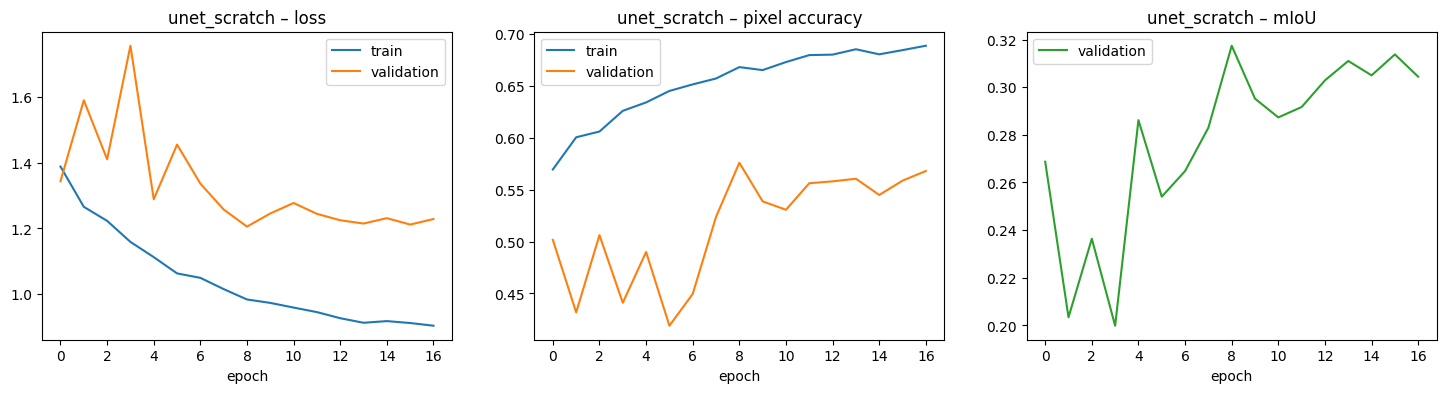

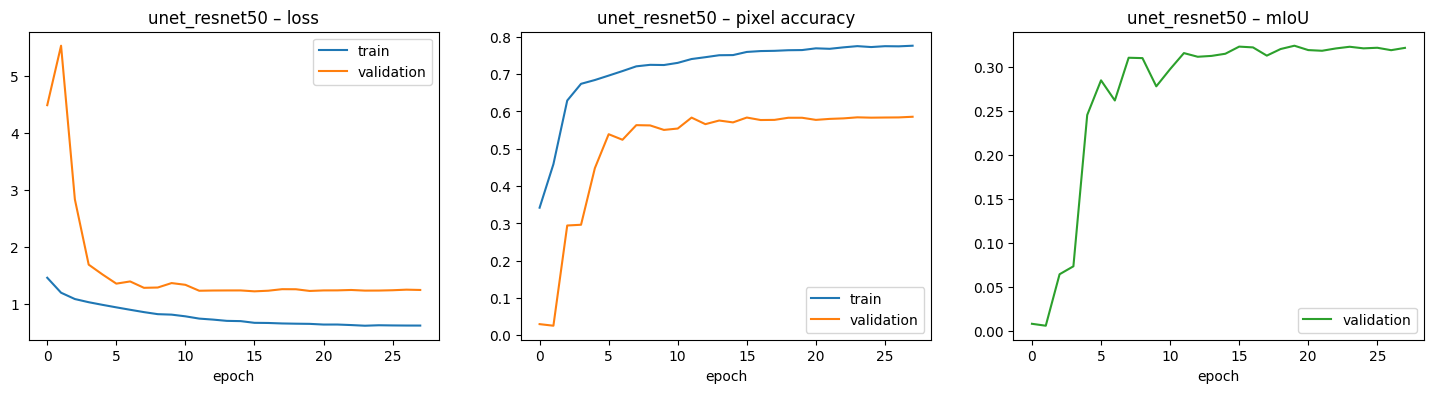

In [17]:
def display_history(name):
    history = json.loads((model_folder / name / "history.json").read_text())

    fig, axes = plt.subplots(1, 3, figsize=(18, 4))
    axes[0].plot(history["loss"], label="train")
    axes[0].plot(history["val_loss"], label="validation")
    axes[0].set_title(f"{name} – loss")

    axes[1].plot(history["masked_accuracy"], label="train")
    axes[1].plot(history["val_masked_accuracy"], label="validation")
    axes[1].set_title(f"{name} – pixel accuracy")

    axes[2].plot(history["val_miou"], color="tab:green", label="validation")
    axes[2].set_title(f"{name} – mIoU")

    for ax in axes:
        ax.set_xlabel("epoch")
        ax.legend()
    plt.show()


for name in experiments:
    display_history(name)

## Comparison on the validation set

The model for the prototype is chosen on **validation** mIoU, not on the test set.

In [18]:
valid_results = {}
for name in experiments:
    model = keras.models.load_model(model_folder / name / "best.keras", compile=False)
    result = scores(confusion(data["validation"]["y"], predict_split(model, valid_ds)))
    valid_results[name] = result
    print(f"{name:<15} OA {result['oa']:.3f}   mIoU {result['miou']:.3f}")

best_name = max(valid_results, key=lambda name: valid_results[name]["miou"])
print("\nSelected model:", best_name)

print(f"\n{'class':<26}" + "".join(f"{name:>16}" for name in experiments))
for i, class_name in enumerate(CLASSES):
    print(f"{class_name:<26}" + "".join(f"{valid_results[name]['iou'][i]:16.3f}" for name in experiments))

unet_scratch    OA 0.576   mIoU 0.317
unet_resnet50   OA 0.583   mIoU 0.324

Selected model: unet_resnet50

class                         unet_scratch   unet_resnet50
Trees (incl. mangroves)              0.421           0.443
Grassland / shrubland                0.394           0.389
Cropland                             0.260           0.244
Built-up                             0.540           0.548
Bare / sparse vegetation             0.077           0.095
Permanent water                      0.526           0.546
Herbaceous wetland                   0.004           0.003


# Final evaluation on the test set (selected model only)

In [19]:
best_model = keras.models.load_model(model_folder / best_name / "best.keras", compile=False)
test_pred = predict_split(best_model, test_ds)
test_cm = confusion(data["test"]["y"], test_pred)
test_result = scores(test_cm)

print(f"Test OA:   {test_result['oa']:.3f}")
print(f"Test mIoU: {test_result['miou']:.3f}\n")
print(f"{'class':<26}{'IoU':>8}{'F1':>8}{'pixels':>12}")
for i, name in enumerate(CLASSES):
    print(f"{name:<26}{test_result['iou'][i]:8.3f}{test_result['f1'][i]:8.3f}{test_cm[i].sum():12,}")

Test OA:   0.642
Test mIoU: 0.374

class                          IoU      F1      pixels
Trees (incl. mangroves)      0.413   0.584  15,075,436
Grassland / shrubland        0.379   0.550   8,908,324
Cropland                     0.500   0.667  10,277,548
Built-up                     0.589   0.742  19,362,908
Bare / sparse vegetation     0.055   0.104     576,284
Permanent water              0.671   0.803   2,360,180
Herbaceous wetland           0.013   0.026      62,424


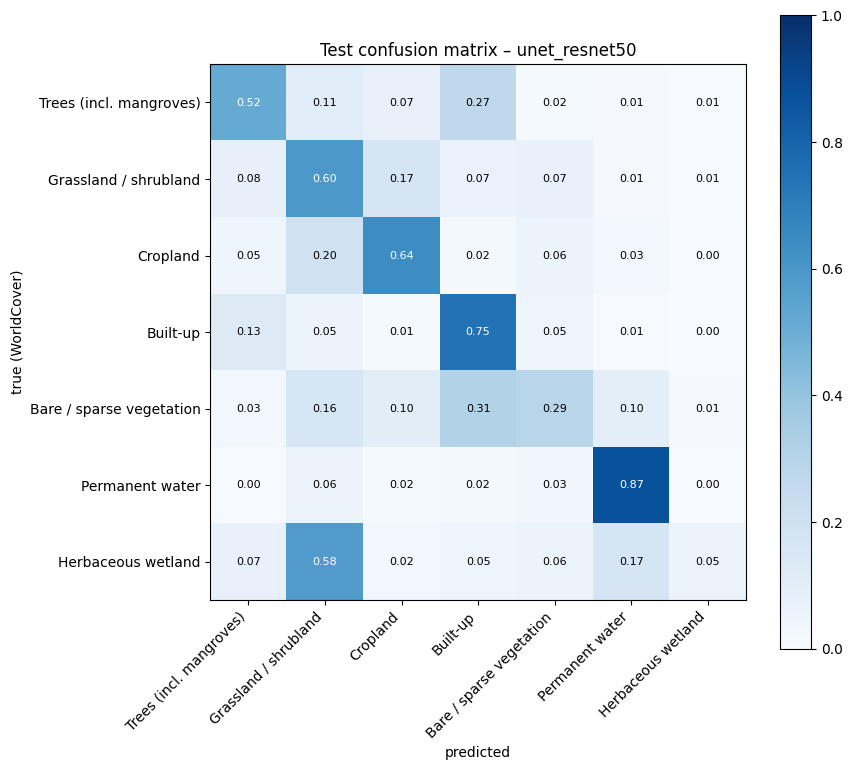

In [20]:
# rows: true class, columns: predicted class, each row sums to 1
row_sums = test_cm.sum(axis=1, keepdims=True)
cm_normalised = np.divide(test_cm, row_sums, out=np.zeros(test_cm.shape), where=row_sums > 0)

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(cm_normalised, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(N_CLASSES), CLASSES, rotation=45, ha="right")
ax.set_yticks(range(N_CLASSES), CLASSES)
ax.set_xlabel("predicted")
ax.set_ylabel("true (WorldCover)")
for i in range(N_CLASSES):
    for j in range(N_CLASSES):
        ax.text(j, i, f"{cm_normalised[i, j]:.2f}", ha="center", va="center",
                color="white" if cm_normalised[i, j] > 0.5 else "black", fontsize=8)
fig.colorbar(im)
ax.set_title(f"Test confusion matrix – {best_name}")
plt.tight_layout()
plt.show()

## Results per test area and per month

The test areas were never seen in training. Differences between areas show how well the model
transfers to new regions; differences between months show seasonal effects.

In [21]:
test_meta = data["test"]["meta"]
test_areas = sorted({row[0] for row in test_meta})
test_months = sorted({int(row[2]) for row in test_meta})

print(f"{'area':<16}{'continent':<16}{'mIoU':>8}{'OA':>8}")
for area in test_areas:
    idx = [i for i, row in enumerate(test_meta) if row[0] == area]
    r = scores(confusion(data["test"]["y"][idx], test_pred[idx]))
    print(f"{area:<16}{test_meta[idx[0]][1]:<16}{r['miou']:8.3f}{r['oa']:8.3f}")

print(f"\n{'month':<8}{'mIoU':>8}{'OA':>8}")
for month in test_months:
    idx = [i for i, row in enumerate(test_meta) if int(row[2]) == month]
    r = scores(confusion(data["test"]["y"][idx], test_pred[idx]))
    print(f"{month:<8}{r['miou']:8.3f}{r['oa']:8.3f}")

area            continent           mIoU      OA
Christchurch    Oceania            0.324   0.617
Cordoba_edge    South America      0.285   0.677
Hanoi_edge      Asia               0.310   0.566
Portland_edge   North America      0.322   0.720
Pretoria_edge   Africa             0.255   0.615
Toulouse        Europe             0.356   0.656

month       mIoU      OA
1          0.389   0.647
4          0.383   0.652
7          0.360   0.624
10         0.369   0.644


## Best and worst test patches

Used for the improvement rounds: is the error a **label** problem, a **data-coverage** problem
or a **model** problem?

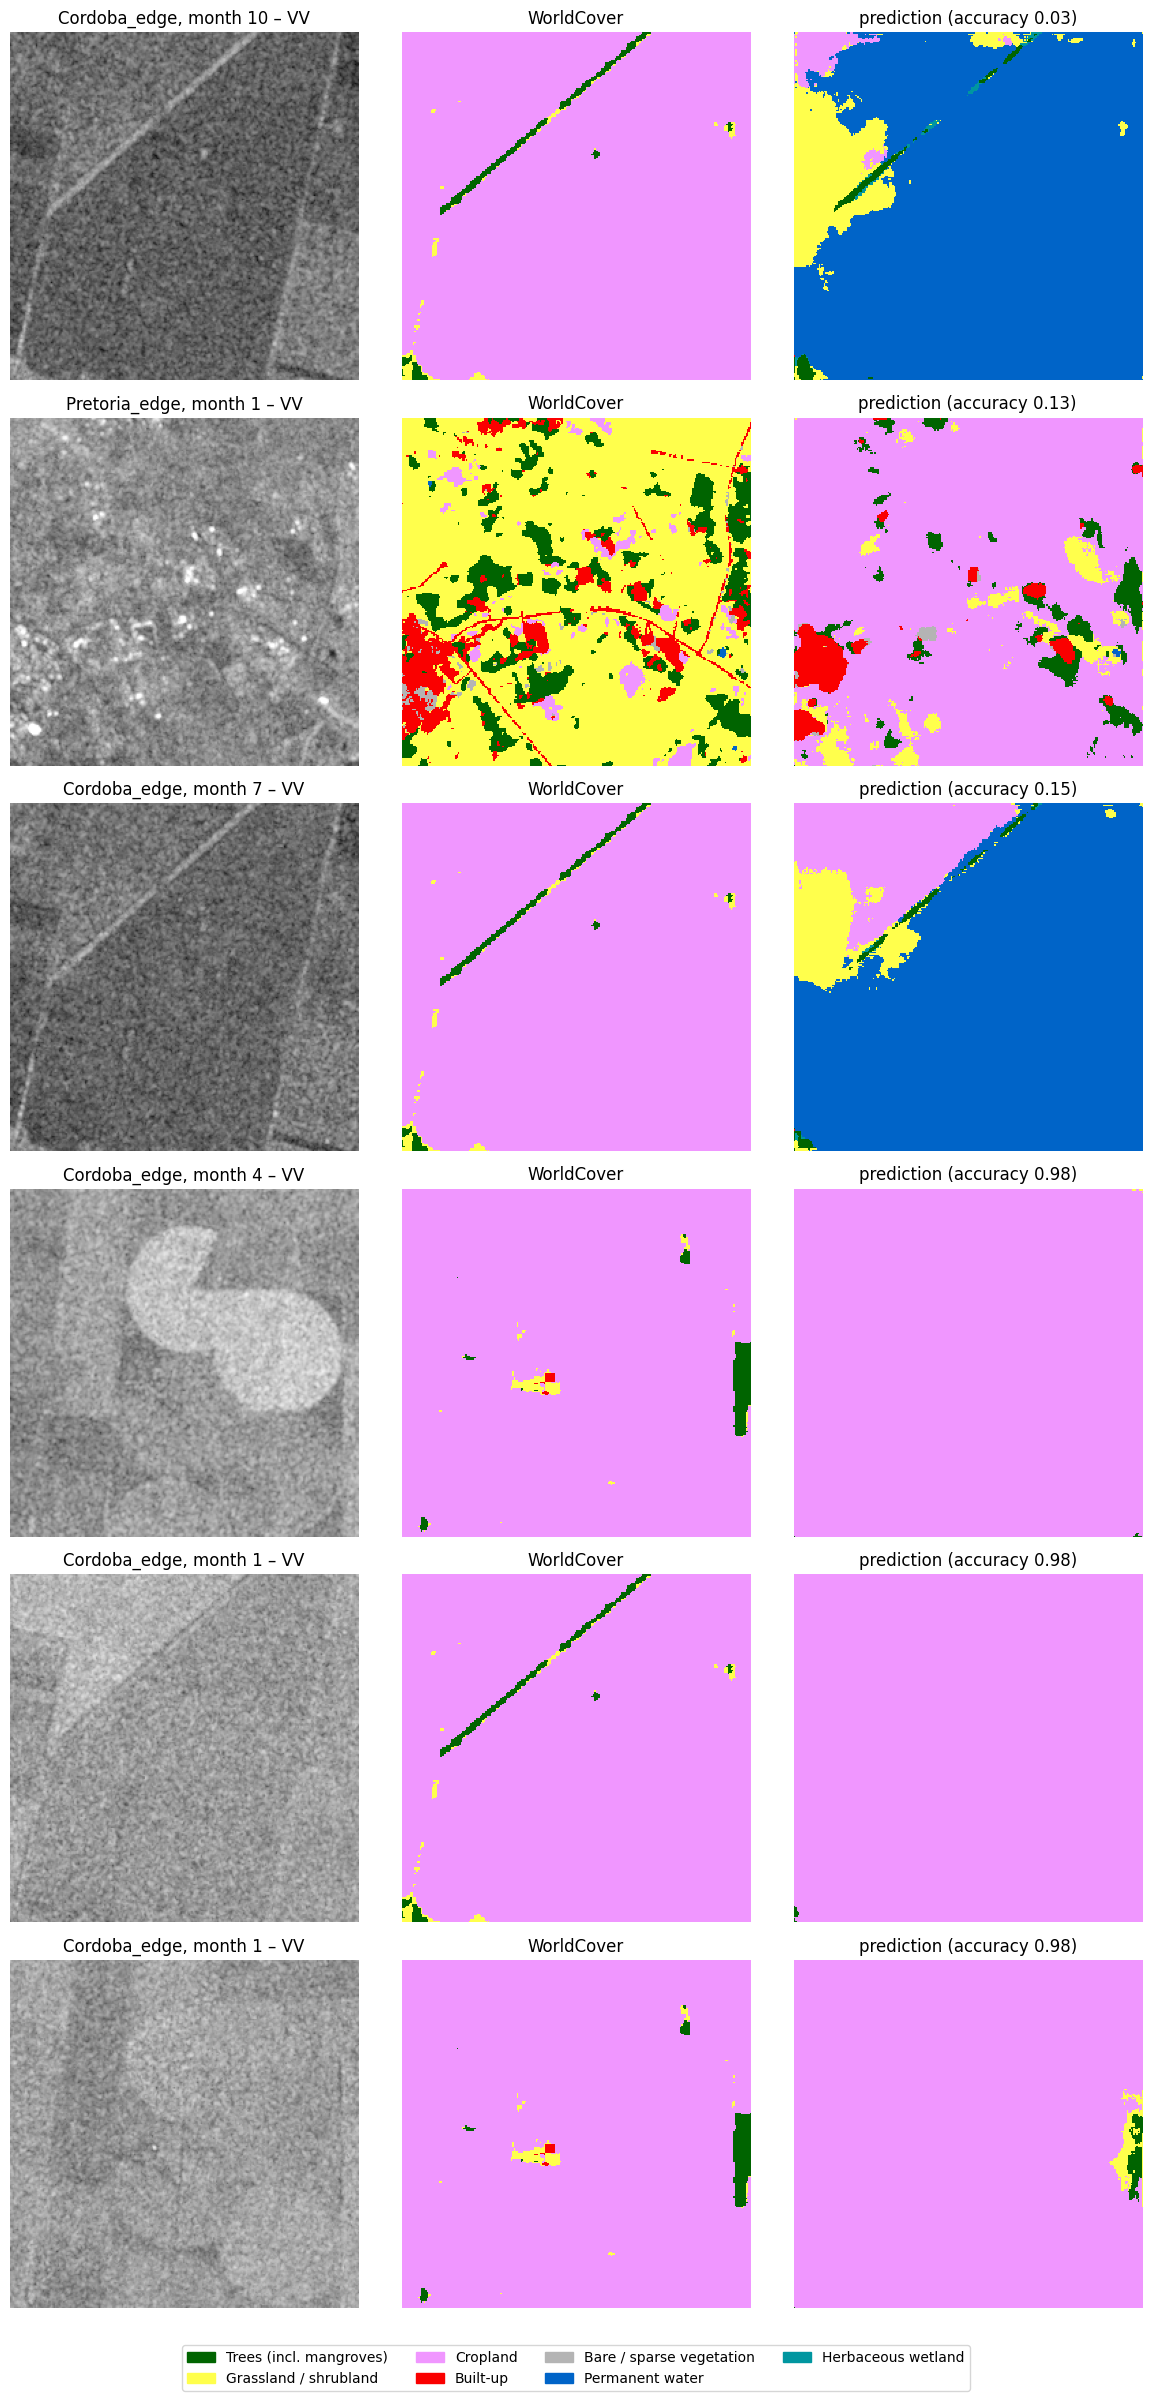

In [22]:
cmap = ListedColormap(COLORS)


def patch_accuracy(i):
    valid = data["test"]["y"][i] != IGNORE
    return (data["test"]["y"][i][valid] == test_pred[i][valid]).mean()


accuracies = np.array([patch_accuracy(i) for i in range(len(test_pred))])
order = np.argsort(accuracies)
chosen = list(order[:3]) + list(order[-3:])

fig, axes = plt.subplots(len(chosen), 3, figsize=(12, 4 * len(chosen)))
for row, i in enumerate(chosen):
    area, continent, month, r, c = test_meta[i]
    label = np.ma.masked_equal(data["test"]["y"][i], IGNORE)

    axes[row, 0].imshow(data["test"]["x"][i][..., 0].astype(np.float32), cmap="gray", vmin=-25, vmax=0)
    axes[row, 0].set_title(f"{area}, month {month} – VV")
    axes[row, 1].imshow(label, cmap=cmap, vmin=-0.5, vmax=N_CLASSES - 0.5, interpolation="nearest")
    axes[row, 1].set_title("WorldCover")
    axes[row, 2].imshow(test_pred[i], cmap=cmap, vmin=-0.5, vmax=N_CLASSES - 0.5, interpolation="nearest")
    axes[row, 2].set_title(f"prediction (accuracy {accuracies[i]:.2f})")
    for ax in axes[row]:
        ax.axis("off")

fig.legend(handles=[Patch(color=c, label=n) for c, n in zip(COLORS, CLASSES)], loc="lower center", ncol=4)
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()

# Save the selected model for the prototype

In [23]:
best_model.save(model_folder / "lulc_model.keras")
(model_folder / "model_info.json").write_text(json.dumps({
    "model": best_name,
    "classes": CLASSES,
    "colors": COLORS,
    "ignore": IGNORE,
    "patch_size": 256,
    "validation_miou": float(valid_results[best_name]["miou"]),
    "test_miou": float(test_result["miou"]),
    "test_oa": float(test_result["oa"]),
}, indent=2))
print("saved models/lulc_model.keras, models/normalisation.json, models/model_info.json")

saved models/lulc_model.keras, models/normalisation.json, models/model_info.json


In [24]:
from pathlib import Path
import json
import zipfile

import numpy as np
from tensorflow import keras

model_dir = Path("models")
model_path = model_dir / "lulc_model.keras"
norm_path = model_dir / "normalisation.json"
info_path = model_dir / "model_info.json"

model = keras.models.load_model(model_path, compile=False)
norm = json.loads(norm_path.read_text())
info = json.loads(info_path.read_text())

# Read just one validation patch from disk.
patches = np.load("data/patches/validation_x.npy", mmap_mode="r")
x = patches[:1].astype(np.float32)

# Use exactly the preprocessing order from training.
x = np.clip(x, np.float32(norm["clip_low"]), np.float32(norm["clip_high"]))
if norm["add_ratio"]:
    difference = x[..., 0:1] - x[..., 1:2]
    x = np.concatenate([x, difference], axis=-1)
x = (x - np.float32(norm["mean"])) / np.float32(norm["std"])

probabilities = model(x, training=False).numpy()
expected = (1, info["patch_size"], info["patch_size"], len(info["classes"]))
assert probabilities.shape == expected, f"Unexpected shape: {probabilities.shape}"
assert np.isfinite(probabilities).all(), "Prediction contains invalid values."
np.testing.assert_allclose(probabilities.sum(axis=-1), 1.0, atol=0.001)

bundle = Path("mannheim_prototype_model.zip")
with zipfile.ZipFile(bundle, "w") as archive:
    for path in [model_path, norm_path, info_path]:
        archive.write(path, arcname=path.name)

print("Saved-model check passed:", probabilities.shape)
print("Prototype files:", bundle.resolve())

Saved-model check passed: (1, 256, 256, 7)
Prototype files: /kaggle/working/mannheim_prototype_model.zip
